# Bài 29 — Learning Curves

**Mục tiêu:** ghi nhận `training loss` và `validation loss` theo epoch cho LSTM và Transformer trên cùng bộ ACL IMDb; vẽ learning curves và dùng chúng để kiểm tra dấu hiệu overfitting, underfitting, hội tụ hoặc bất ổn.



## 1. Nạp thư viện và thiết lập seed

Cell kế tiếp cố định seed để kết quả dễ tái lập. Nếu Colab có GPU, TensorFlow sẽ dùng thiết bị phù hợp.

In [ ]:
# Cài đặt seed và nạp thư viện
import os
import random
import tarfile
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: []


## 2. Tải dữ liệu và tạo train/validation split

Ưu tiên ACL IMDb của Stanford; nếu kết nối bị từ chối, thử bộ IMDb qua Keras. Tập test được giữ riêng và không tham gia huấn luyện hay vẽ learning curves.

In [ ]:
DATA_URL = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
DATA_DIR = Path("/content/aclImdb")
ARCHIVE_PATH = Path("/content/aclImdb_v1.tar.gz")

# Ưu tiên bản raw ACL IMDb của Stanford. Nếu kết nối bị từ chối,
# dùng bản IMDb tương ứng do Keras tải từ kho dữ liệu của TensorFlow.
if (DATA_DIR / "train" / "pos").exists():
    print("Dùng ACL IMDb đã có trong runtime.")
else:
    try:
        if not ARCHIVE_PATH.exists():
            print("Đang tải ACL IMDb từ Stanford (~84 MB)...")
            urllib.request.urlretrieve(DATA_URL, ARCHIVE_PATH)
        print("Đang giải nén dataset...")
        with tarfile.open(ARCHIVE_PATH, "r:gz") as archive:
            archive.extractall(path="/content", filter="data")
    except Exception as download_error:
        # Xóa file tải dở để lần chạy sau không nhầm file hỏng là archive hợp lệ.
        ARCHIVE_PATH.unlink(missing_ok=True)
        print("Không tải được archive Stanford:", repr(download_error))
        print("Đang thử bản IMDb dự phòng qua Keras/TensorFlow...")
        try:
            (encoded_train, labels_train), (encoded_test, labels_test) = (
                tf.keras.datasets.imdb.load_data(path="imdb.npz", num_words=None, seed=SEED)
            )
            word_index = tf.keras.datasets.imdb.get_word_index()
            reverse_word_index = {index + 3: word for word, index in word_index.items()}
            reverse_word_index.update({0: "<PAD>", 1: "<START>", 2: "<OOV>", 3: "<UNUSED>"})

            def decode_review(sequence):
                # Bỏ các token điều khiển của bản đã mã hóa; giữ lại nội dung review.
                return " ".join(
                    reverse_word_index.get(int(token), "<UNK>")
                    for token in sequence if int(token) not in {0, 1, 2, 3}
                )

            all_train_texts = [decode_review(seq) for seq in encoded_train]
            all_train_labels = np.asarray(labels_train, dtype=np.int32)
            test_texts = [decode_review(seq) for seq in encoded_test]
            y_test = np.asarray(labels_test, dtype=np.int32)
            print("Đã tải IMDb qua Keras:", len(all_train_texts), "train /", len(test_texts), "test")
        except Exception as fallback_error:
            raise RuntimeError(
                "Không tải được dữ liệu từ Stanford hoặc Keras. Kiểm tra kết nối Internet "
                "của Colab rồi chạy lại cell này."
            ) from fallback_error

# Nếu đã có file ACL IMDb raw, nạp thư mục chuẩn pos/neg.
if "all_train_texts" not in globals():
    def read_split(split):
        texts, labels = [], []
        for label_name, label_id in (("neg", 0), ("pos", 1)):
            folder = DATA_DIR / split / label_name
            for file_path in sorted(folder.glob("*.txt")):
                texts.append(file_path.read_text(encoding="utf-8", errors="replace").strip())
                labels.append(label_id)
        return texts, np.asarray(labels, dtype=np.int32)

    all_train_texts, all_train_labels = read_split("train")
    test_texts, y_test = read_split("test")

train_texts, val_texts, y_train, y_val = train_test_split(
    all_train_texts, all_train_labels, test_size=0.1,
    random_state=SEED, stratify=all_train_labels
)

print(f"Train: {len(train_texts):,} | Validation: {len(val_texts):,} | Test: {len(test_texts):,}")
print("Label counts in train (negative, positive):", np.bincount(y_train))


Đang tải ACL IMDb từ Stanford (~84 MB)...
Không tải được archive Stanford: URLError(ConnectionRefusedError(111, 'Connection refused'))
Đang thử bản IMDb dự phòng qua Keras/TensorFlow...
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
Đã tải IMDb qua Keras: 25000 train / 25000 test
Train: 22,500 | Validation: 2,500 | Test: 25,000
Label counts in train (negative, positive): [11250 11250]


## 3. Tokenize và chuẩn bị dữ liệu

Hai mô hình dùng chung vocabulary, độ dài chuỗi, batch size và số epoch để đường loss có thể so sánh. Có thể tăng `EPOCHS` nếu cần quan sát xu hướng dài hơn.

In [ ]:
MAX_VOCAB_SIZE = 20_000
MAX_LEN = 200
EMBEDDING_DIM = 64
HIDDEN_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 3
LEARNING_RATE = 0.001

tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(train_texts)
vocab_size = min(MAX_VOCAB_SIZE, len(tokenizer.word_index) + 1)

def encode_and_pad(texts):
    sequences = tokenizer.texts_to_sequences(texts)
    return pad_sequences(
        sequences, maxlen=MAX_LEN, padding="post", truncating="post", value=0
    )

X_train = encode_and_pad(train_texts)
X_val = encode_and_pad(val_texts)
X_test = encode_and_pad(test_texts)

print("Vocabulary size:", vocab_size)
print("Tensor shapes — train / validation / test:", X_train.shape, X_val.shape, X_test.shape)


Vocabulary size: 20000
Tensor shapes — train / validation / test: (22500, 200) (2500, 200) (25000, 200)


## 4. Định nghĩa LSTM và Transformer

Giữ kiến trúc của Bài 21 để Bài 29 tập trung vào diễn biến loss trong quá trình huấn luyện.

In [ ]:
class SinusoidalPositionEncoding(layers.Layer):
    def call(self, embeddings):
        length = tf.shape(embeddings)[1]
        dimension = tf.shape(embeddings)[2]
        positions = tf.cast(tf.range(length)[:, tf.newaxis], tf.float32)
        dims = tf.cast(tf.range(dimension)[tf.newaxis, :], tf.float32)
        angle_rates = tf.pow(10000.0, -(2.0 * tf.floor(dims / 2.0)) / tf.cast(dimension, tf.float32))
        angles = positions * angle_rates
        even_channels = tf.equal(tf.math.floormod(tf.range(dimension), 2), 0)[tf.newaxis, :]
        encoding = tf.where(even_channels, tf.sin(angles), tf.cos(angles))
        encoding = encoding[tf.newaxis, :, :]
        return embeddings + tf.cast(encoding, embeddings.dtype)

class TransformerEncoderBlock(layers.Layer):
    def __init__(self, d_model, num_heads, ff_dim, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.mha = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=d_model // num_heads, dropout=dropout_rate
        )
        self.ffn = models.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(d_model),
        ])
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = layers.Dropout(dropout_rate)
        self.dropout2 = layers.Dropout(dropout_rate)

    def call(self, inputs, training=None):
        x, valid_tokens = inputs
        # Mask các key là padding; broadcast qua mọi query và mọi attention head.
        attention_mask = valid_tokens[:, tf.newaxis, :]
        attended = self.mha(
            query=x, value=x, key=x, attention_mask=attention_mask, training=training
        )
        x = self.norm1(x + self.dropout1(attended, training=training))
        transformed = self.ffn(x, training=training)
        return self.norm2(x + self.dropout2(transformed, training=training))

class MaskedMeanPooling(layers.Layer):
    def call(self, inputs):
        sequence, valid_tokens = inputs
        mask = tf.cast(valid_tokens[:, :, tf.newaxis], sequence.dtype)
        summed = tf.reduce_sum(sequence * mask, axis=1)
        counts = tf.maximum(tf.reduce_sum(mask, axis=1), tf.ones_like(tf.reduce_sum(mask, axis=1)))
        return summed / counts

def build_lstm_model():
    review = layers.Input(shape=(MAX_LEN,), dtype="int32", name="token_ids")
    x = layers.Embedding(vocab_size, EMBEDDING_DIM, mask_zero=True, name="embedding")(review)
    x = layers.LSTM(HIDDEN_SIZE, name="lstm")(x)
    output = layers.Dense(1, activation="sigmoid", name="sentiment")(x)
    return models.Model(review, output, name="LSTM")

def build_transformer_model():
    review = layers.Input(shape=(MAX_LEN,), dtype="int32", name="token_ids")
    valid_tokens = layers.Lambda(lambda ids: tf.not_equal(ids, 0), name="valid_token_mask")(review)
    x = layers.Embedding(vocab_size, EMBEDDING_DIM, name="embedding")(review)
    x = SinusoidalPositionEncoding(name="positional_encoding")(x)
    x = TransformerEncoderBlock(
        d_model=EMBEDDING_DIM, num_heads=4, ff_dim=128, dropout_rate=0.1,
        name="transformer_encoder"
    )([x, valid_tokens])
    x = MaskedMeanPooling(name="masked_mean_pooling")([x, valid_tokens])
    x = layers.Dropout(0.1)(x)
    output = layers.Dense(1, activation="sigmoid", name="sentiment")(x)
    return models.Model(review, output, name="Transformer")

def compile_model(model):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="binary_crossentropy", metrics=["accuracy"]
    )
    return model

lstm_model = compile_model(build_lstm_model())
transformer_model = compile_model(build_transformer_model())

print("Common settings:", {
    "max_vocab": MAX_VOCAB_SIZE, "max_length": MAX_LEN,
    "embedding_dim": EMBEDDING_DIM, "batch_size": BATCH_SIZE,
    "epochs": EPOCHS, "learning_rate": LEARNING_RATE,
})
print("LSTM parameters:", f"{lstm_model.count_params():,}")
print("Transformer parameters:", f"{transformer_model.count_params():,}")


Common settings: {'max_vocab': 20000, 'max_length': 200, 'embedding_dim': 64, 'batch_size': 64, 'epochs': 3, 'learning_rate': 0.001}
LSTM parameters: 1,313,089
Transformer parameters: 1,313,537


## 5. Huấn luyện và lưu loss mỗi epoch

Keras `History` lưu `loss` và `val_loss` sau mỗi epoch. Các giá trị này là dữ liệu nguồn cho biểu đồ và bảng ở phần sau.

In [ ]:
histories = {}
trained_models = {"LSTM": lstm_model, "Transformer": transformer_model}
training_times = {}

for model_name, model in trained_models.items():
    print(f"\n{'=' * 18} {model_name} {'=' * 18}")
    tf.keras.utils.set_random_seed(SEED)
    start = time.perf_counter()
    history = model.fit(
        X_train, y_train, validation_data=(X_val, y_val),
        epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True, verbose=2
    )
    training_times[model_name] = time.perf_counter() - start
    histories[model_name] = history.history
    print(f"Training time: {training_times[model_name]:.2f} seconds")



================== LSTM ==================
Epoch 1/3
352/352 - 80s - 226ms/step - accuracy: 0.7666 - loss: 0.4662 - val_accuracy: 0.8572 - val_loss: 0.3375
Epoch 2/3
352/352 - 82s - 232ms/step - accuracy: 0.9014 - loss: 0.2639 - val_accuracy: 0.8488 - val_loss: 0.3707
Epoch 3/3
352/352 - 74s - 211ms/step - accuracy: 0.9223 - loss: 0.2094 - val_accuracy: 0.8588 - val_loss: 0.4284
Training time: 236.11 seconds

================== Transformer ==================
Epoch 1/3
352/352 - 271s - 769ms/step - accuracy: 0.7332 - loss: 0.4962 - val_accuracy: 0.8616 - val_loss: 0.3215
Epoch 2/3
352/352 - 269s - 764ms/step - accuracy: 0.8994 - loss: 0.2530 - val_accuracy: 0.8804 - val_loss: 0.3082
Epoch 3/3
352/352 - 315s - 894ms/step - accuracy: 0.9343 - loss: 0.1718 - val_accuracy: 0.8608 - val_loss: 0.3874
Training time: 854.65 seconds


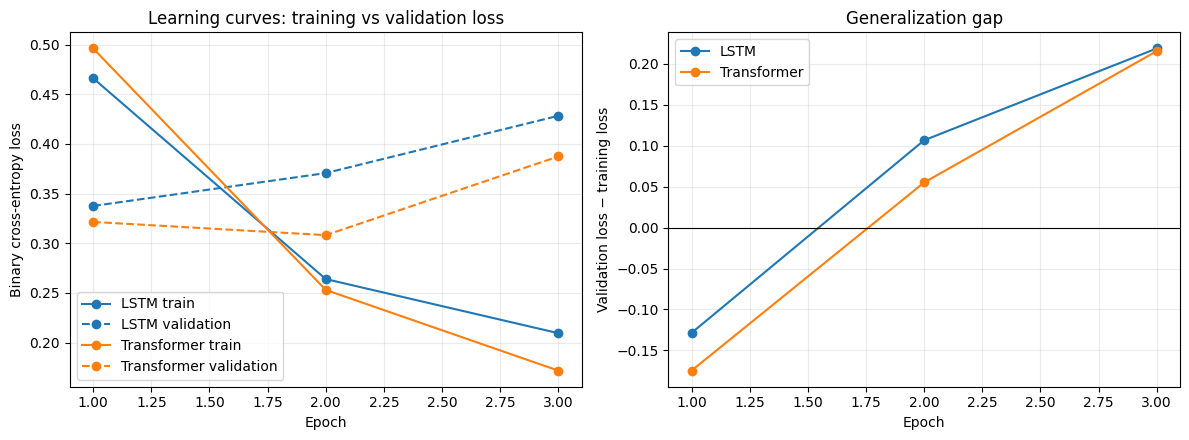

,model,epoch,training_loss,validation_loss,generalization_gap
0,LSTM,1,0.4662,0.3375,-0.1286
1,LSTM,2,0.2639,0.3707,0.1067
2,LSTM,3,0.2094,0.4284,0.2189
3,Transformer,1,0.4962,0.3215,-0.1747
4,Transformer,2,0.2530,0.3082,0.0552
5,Transformer,3,0.1718,0.3874,0.2156


Đã lưu biểu đồ: /content/bai29_learning_curves.png
Đã lưu bảng loss: /content/bai29_learning_curves.csv


In [ ]:
# Vẽ learning curves và xuất dữ liệu cho báo cáo
import matplotlib.pyplot as plt

rows = []
colors = {"LSTM": "tab:blue", "Transformer": "tab:orange"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)

for model_name, history in histories.items():
    epochs_range = range(1, len(history["loss"]) + 1)
    axes[0].plot(epochs_range, history["loss"], marker="o",
                 color=colors[model_name], label=f"{model_name} train")
    axes[0].plot(epochs_range, history["val_loss"], marker="o", linestyle="--",
                 color=colors[model_name], label=f"{model_name} validation")
    for epoch, (train_loss, val_loss) in enumerate(zip(history["loss"], history["val_loss"]), start=1):
        rows.append({"model": model_name, "epoch": epoch,
                     "training_loss": float(train_loss), "validation_loss": float(val_loss),
                     "generalization_gap": float(val_loss - train_loss)})

axes[0].set(title="Learning curves: training vs validation loss",
            xlabel="Epoch", ylabel="Binary cross-entropy loss")
axes[0].grid(True, alpha=0.25)
axes[0].legend()

# So sánh riêng độ chênh validation - training loss giữa các mô hình.
for model_name, history in histories.items():
    gap = [v - t for t, v in zip(history["loss"], history["val_loss"])]
    axes[1].plot(range(1, len(gap) + 1), gap, marker="o",
                 color=colors[model_name], label=model_name)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(title="Generalization gap", xlabel="Epoch",
            ylabel="Validation loss − training loss")
axes[1].grid(True, alpha=0.25)
axes[1].legend()
fig.tight_layout()
fig.savefig("/content/bai29_learning_curves.png", dpi=160, bbox_inches="tight")
plt.show()

curve_df = pd.DataFrame(rows)
display(curve_df.round(4))
curve_df.to_csv("/content/bai29_learning_curves.csv", index=False)
print("Đã lưu biểu đồ: /content/bai29_learning_curves.png")
print("Đã lưu bảng loss: /content/bai29_learning_curves.csv")


In [ ]:
# Gợi ý chẩn đoán sơ bộ từ xu hướng loss
def diagnose_curve(train_loss, val_loss):
    train_loss = list(map(float, train_loss))
    val_loss = list(map(float, val_loss))
    notes = []

    if len(val_loss) >= 3 and val_loss[-1] > val_loss[-2] > val_loss[-3] and train_loss[-1] < train_loss[-2]:
        notes.append("Validation loss tăng liên tiếp trong khi training loss còn giảm: dấu hiệu overfitting cần kiểm tra.")
    elif val_loss[-1] - train_loss[-1] > 0.15:
        notes.append("Khoảng cách validation-training loss đang lớn: có thể có overfitting; kiểm tra thêm đường cong và metric.")
    if len(train_loss) >= 3 and all(train_loss[i] >= train_loss[i-1] for i in range(1, len(train_loss))):
        notes.append("Training loss không giảm: có thể mô hình chưa học được hoặc quá trình huấn luyện bất ổn.")
    elif len(train_loss) >= 3 and abs(train_loss[-1] - train_loss[-2]) < 0.01 and abs(val_loss[-1] - val_loss[-2]) < 0.01:
        notes.append("Hai loss gần như ổn định ở các epoch cuối: có dấu hiệu hội tụ trong khoảng quan sát.")
    if len(train_loss) >= 3 and any(train_loss[i] > train_loss[i-1] for i in range(1, len(train_loss))):
        notes.append("Training loss có epoch tăng: kiểm tra dao động, learning rate và độ ổn định.")
    if not notes:
        notes.append("Chưa thấy dấu hiệu rõ theo các ngưỡng đơn giản; cần đọc biểu đồ và so sánh thêm metric.")
    return notes

for model_name, history in histories.items():
    print(f"\n{model_name}:")
    for note in diagnose_curve(history["loss"], history["val_loss"]):
        print("-", note)



LSTM:
- Validation loss tăng liên tiếp trong khi training loss còn giảm: dấu hiệu overfitting cần kiểm tra.

Transformer:
- Khoảng cách validation-training loss đang lớn: có thể có overfitting; kiểm tra thêm đường cong và metric.
